<a href="https://colab.research.google.com/github/Ashwini4856/BIS_LAB/blob/main/Parallel_cellular_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 0 Best Fitness: 0.01948
Iteration: 10 Best Fitness: 0.02883
Iteration: 20 Best Fitness: 0.02883
Iteration: 30 Best Fitness: 0.02895
Iteration: 40 Best Fitness: 0.02895
Iteration: 50 Best Fitness: 0.02895
Iteration: 60 Best Fitness: 0.02895
Iteration: 70 Best Fitness: 0.02895
Iteration: 80 Best Fitness: 0.02895
Iteration: 90 Best Fitness: 0.02906

OPTIMAL HOSPITAL RESOURCE ALLOCATION

Department       Doctors  Nurses  Beds
Emergency              5      10    15
Cardiology             4       8    10
Orthopedics            3       6    11
Neurology              0       0     4

Total Allocated Resources:
Doctors: 12
Nurses: 24
Beds: 40

Best Fitness: 0.02918


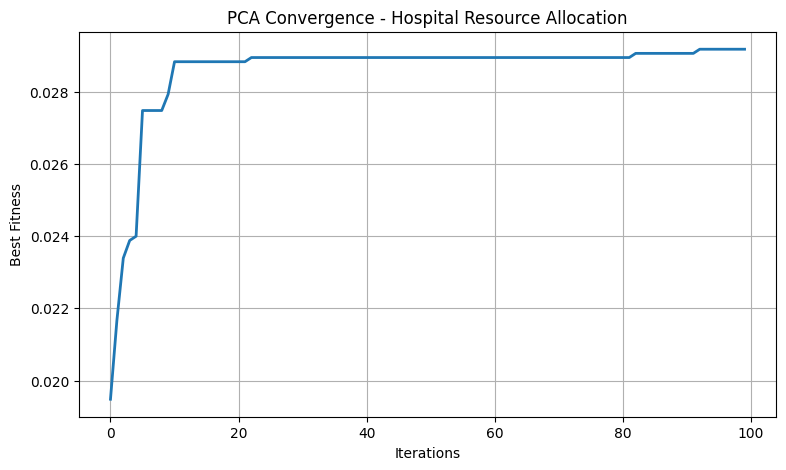

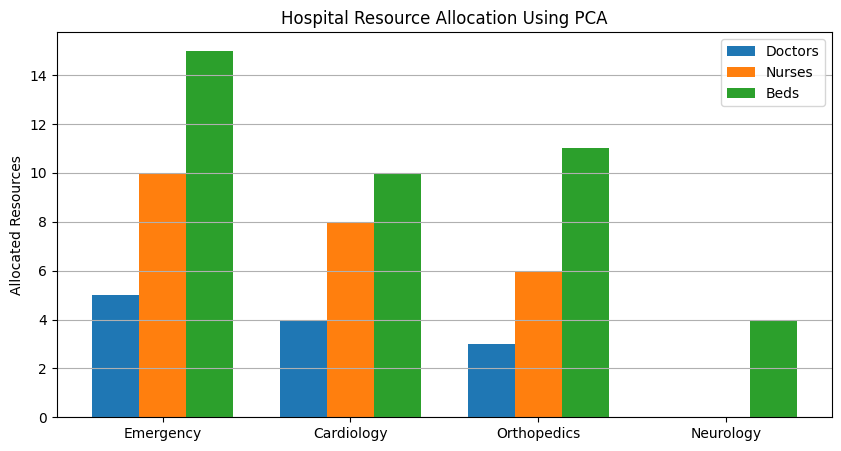

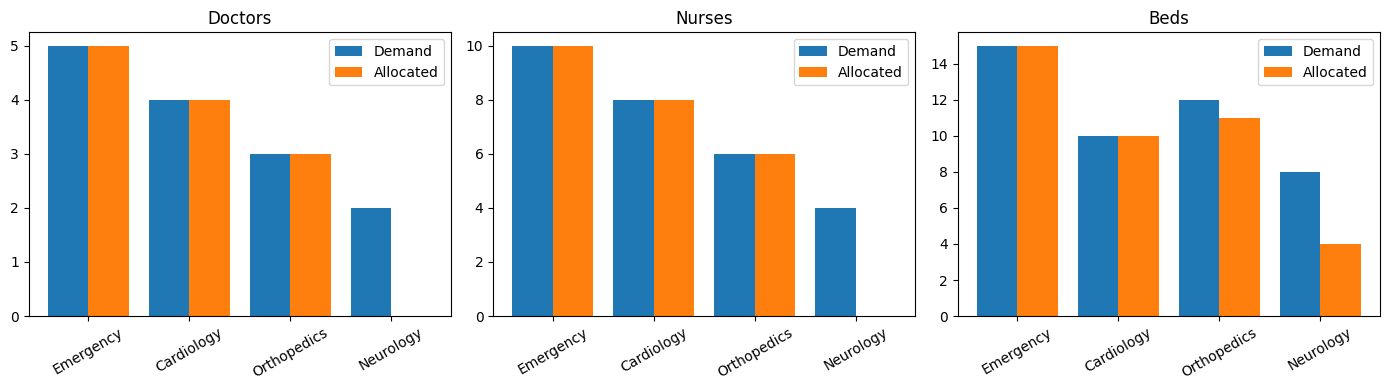

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

# Hospital data
departments = [
    "Emergency",
    "Cardiology",
    "Orthopedics",
    "Neurology"
]

demand = np.array([
    [5, 10, 15],
    [4, 8, 10],
    [3, 6, 12],
    [2, 4, 8]
])

available = np.array([12, 24, 40])

# Department priority weights
priority = np.array([1.5, 1.3, 1.1, 1.0])

# PCA parameters
POP_SIZE = 16
GRID_SIZE = 4
ITERATIONS = 100
MUTATION_RATE = 0.25
WORKERS = 4

np.random.seed(42)

# Generate a feasible allocation
def generate_solution():
    solution = np.zeros_like(demand)

    for j in range(3):
        solution[:, j] = np.random.multinomial(
            available[j],
            demand[:, j] / demand[:, j].sum()
        )

    return solution


# Repair allocation to satisfy resource limits
def repair(solution):
    solution = np.maximum(0, np.round(solution)).astype(int)

    for j in range(3):
        while solution[:, j].sum() > available[j]:
            indexes = np.where(solution[:, j] > 0)[0]
            i = np.random.choice(indexes)
            solution[i, j] -= 1

        while solution[:, j].sum() < available[j]:
            i = np.random.randint(0, len(departments))
            solution[i, j] += 1

    return solution


# Fitness calculation
def fitness(solution):

    shortage = np.maximum(demand - solution, 0)

    # Weighted shortage penalty
    shortage_cost = np.sum(
        shortage * np.array([5, 3, 2]) * priority[:, None]
    )

    # Workload imbalance
    satisfaction = np.mean(
        np.minimum(solution / demand, 1),
        axis=1
    )

    imbalance = np.std(satisfaction) * 10

    total_cost = shortage_cost + 0.3 * imbalance

    return 1 / (1 + total_cost)


# Von Neumann neighborhood
def get_neighbors(index):

    row = index // GRID_SIZE
    col = index % GRID_SIZE

    neighbors = [
        ((row - 1) % GRID_SIZE) * GRID_SIZE + col,
        ((row + 1) % GRID_SIZE) * GRID_SIZE + col,
        row * GRID_SIZE + (col - 1) % GRID_SIZE,
        row * GRID_SIZE + (col + 1) % GRID_SIZE
    ]

    return neighbors


# Create initial population
population = [generate_solution() for _ in range(POP_SIZE)]

# Store convergence
best_history = []
best_solution = None
best_fitness = -1

# Parallel Cellular Algorithm
with ThreadPoolExecutor(max_workers=WORKERS) as executor:

    for iteration in range(ITERATIONS):

        # Evaluate all cells in parallel
        scores = list(executor.map(fitness, population))

        # Find global best
        current_best = np.argmax(scores)

        if scores[current_best] > best_fitness:
            best_fitness = scores[current_best]
            best_solution = population[current_best].copy()

        best_history.append(best_fitness)

        new_population = []

        # Update cells in parallel
        def update_cell(i):

            neighbors = get_neighbors(i)

            # Find best neighboring cell
            best_neighbor = max(
                neighbors,
                key=lambda n: scores[n]
            )

            current = population[i]
            neighbor_best = population[best_neighbor]

            # Combine current and neighboring solutions
            mask = np.random.random(demand.shape) < 0.5

            child = np.where(
                mask,
                current,
                neighbor_best
            )

            # Mutation
            if np.random.random() < MUTATION_RATE:

                for j in range(3):
                    a, b = np.random.choice(4, 2, replace=False)

                    if child[a, j] > 0:
                        child[a, j] -= 1
                        child[b, j] += 1

            child = repair(child)

            # Greedy replacement
            if fitness(child) >= scores[i]:
                return child

            return current.copy()

        new_population = list(
            executor.map(update_cell, range(POP_SIZE))
        )

        # Synchronize all cells
        population = new_population

        if iteration % 10 == 0:
            print(
                "Iteration:", iteration,
                "Best Fitness:", round(best_fitness, 5)
            )


# Display final result
print("\nOPTIMAL HOSPITAL RESOURCE ALLOCATION")

print("\nDepartment       Doctors  Nurses  Beds")

for i in range(4):
    print(
        f"{departments[i]:15}",
        f"{best_solution[i, 0]:8}",
        f"{best_solution[i, 1]:7}",
        f"{best_solution[i, 2]:5}"
    )

print("\nTotal Allocated Resources:")
print("Doctors:", best_solution[:, 0].sum())
print("Nurses:", best_solution[:, 1].sum())
print("Beds:", best_solution[:, 2].sum())

print("\nBest Fitness:", round(best_fitness, 5))

# Graph 1: Convergence
plt.figure(figsize=(9, 5))
plt.plot(best_history, linewidth=2)
plt.title("PCA Convergence - Hospital Resource Allocation")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()

# Graph 2: Resource allocation
x = np.arange(len(departments))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(
    x - width,
    best_solution[:, 0],
    width,
    label="Doctors"
)

plt.bar(
    x,
    best_solution[:, 1],
    width,
    label="Nurses"
)

plt.bar(
    x + width,
    best_solution[:, 2],
    width,
    label="Beds"
)

plt.xticks(x, departments)
plt.ylabel("Allocated Resources")
plt.title("Hospital Resource Allocation Using PCA")
plt.legend()
plt.grid(axis="y")
plt.show()

# Graph 3: Demand versus allocation
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for j, name in enumerate(["Doctors", "Nurses", "Beds"]):
    axes[j].bar(
        x - 0.2, demand[:, j],
        width=0.4, label="Demand"
    )
    axes[j].bar(
        x + 0.2, best_solution[:, j],
        width=0.4, label="Allocated"
    )
    axes[j].set_title(name)
    axes[j].set_xticks(x)
    axes[j].set_xticklabels(departments, rotation=30)
    axes[j].legend()

plt.tight_layout()
plt.show()
